In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

In [3]:
#Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
sns.set_theme(style="whitegrid", palette="muted")
%matplotlib inline
plt.rcParams['figure.figsize']=(10, 6)

In [5]:
#Data ingestion and inspection
iris=load_iris()
df=pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target']=iris.target

In [8]:
print(df.head(10))

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  target
0                5.1               3.5                1.4               0.2       0
1                4.9               3.0                1.4               0.2       0
2                4.7               3.2                1.3               0.2       0
3                4.6               3.1                1.5               0.2       0
4                5.0               3.6                1.4               0.2       0
5                5.4               3.9                1.7               0.4       0
6                4.6               3.4                1.4               0.3       0
7                5.0               3.4                1.5               0.2       0
8                4.4               2.9                1.4               0.2       0
9                4.9               3.1                1.5               0.1       0


In [7]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
None


In [ ]:
#Statistical summary of the dataset
print(df.describe().T)

                   count      mean       std  min  25%   50%  75%  max
sepal length (cm)  150.0  5.843333  0.828066  4.3  5.1  5.80  6.4  7.9
sepal width (cm)   150.0  3.057333  0.435866  2.0  2.8  3.00  3.3  4.4
petal length (cm)  150.0  3.758000  1.765298  1.0  1.6  4.35  5.1  6.9
petal width (cm)   150.0  1.199333  0.762238  0.1  0.3  1.30  1.8  2.5
target             150.0  1.000000  0.819232  0.0  0.0  1.00  2.0  2.0


In [10]:
# Data Quality & Integrity Checks
missing_count=df.isnull().sum()
missing_pct=(missing_count/len(df))*100
data_quality = pd.DataFrame({'Missing Count': missing_count, 'Missing %': missing_pct})
print("\n--> Missing Value Summary:")
print(data_quality)


--> Missing Value Summary:
                   Missing Count  Missing %
sepal length (cm)              0        0.0
sepal width (cm)               0        0.0
petal length (cm)              0        0.0
petal width (cm)               0        0.0
target                         0        0.0


In [14]:
duplicate_count=df.duplicated().sum()
print(duplicate_count)
if (duplicate_count > 0):
    df=df.drop_duplicates().reset_index(drop=True)

1


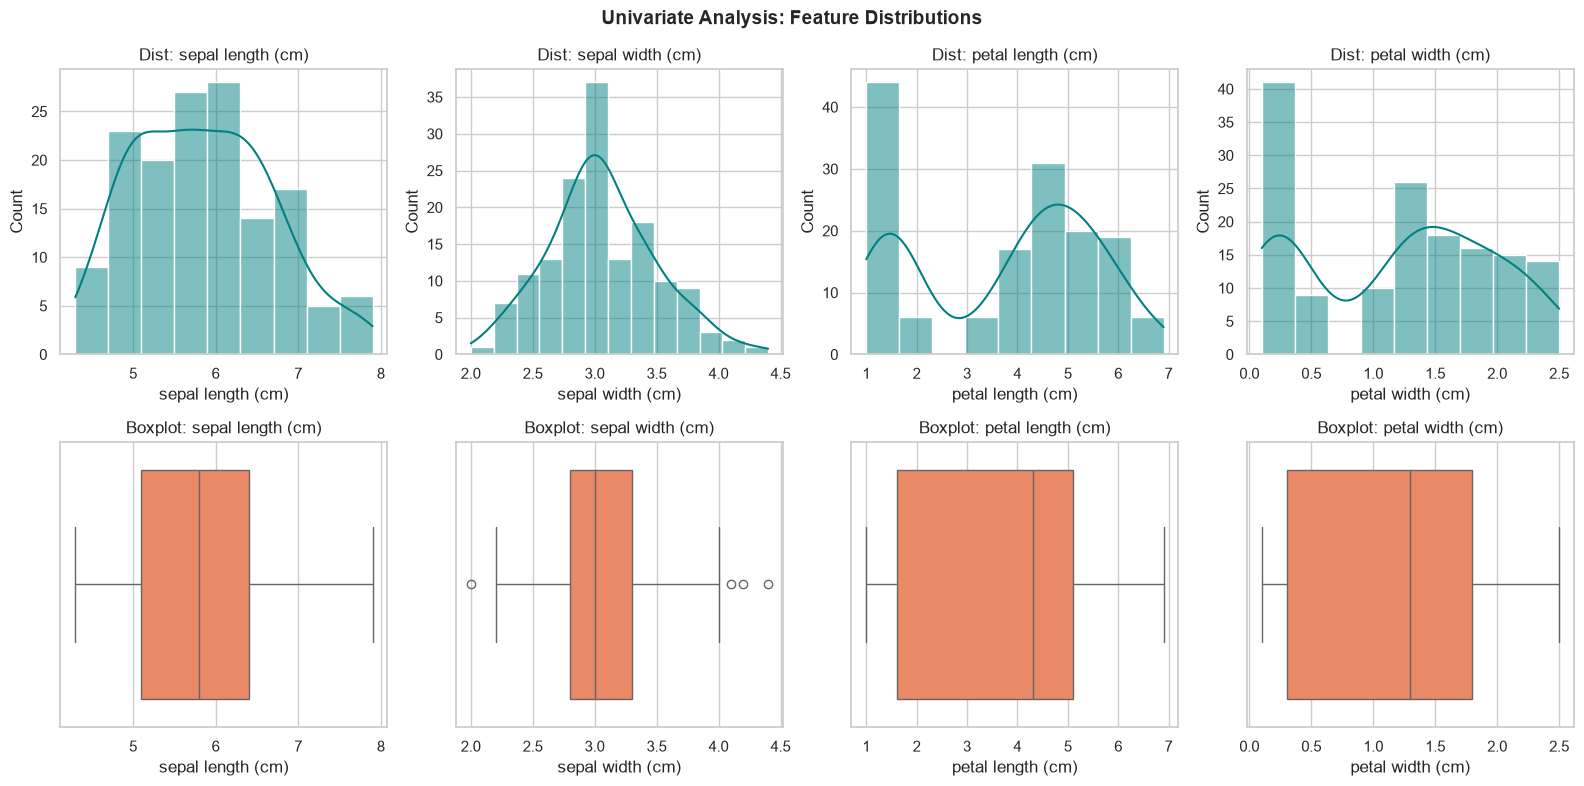

In [ ]:
#Univariate Analysis
feature_cols=iris.feature_names
fig, axes=plt.subplots(2,4, figsize=(16, 8))
fig.suptitle("Univariate Analysis: Feature Distributions", fontsize=14, fontweight='bold')

for i,col in enumerate(feature_cols):
    sns.histplot(df[col], kde=True, ax=axes[0, i], color='Teal')
    axes[0, i].set_title(f"Dist: {col}")

    sns.boxplot(x=df[col], ax=axes[1,i], color='coral')
    axes[1, i].set_title(f"Boxplot: {col}")

plt.tight_layout()
plt.show()


In [17]:
print(df[feature_cols].skew())

sepal length (cm)    0.312826
sepal width (cm)     0.307149
petal length (cm)   -0.263101
petal width (cm)    -0.090076
dtype: float64


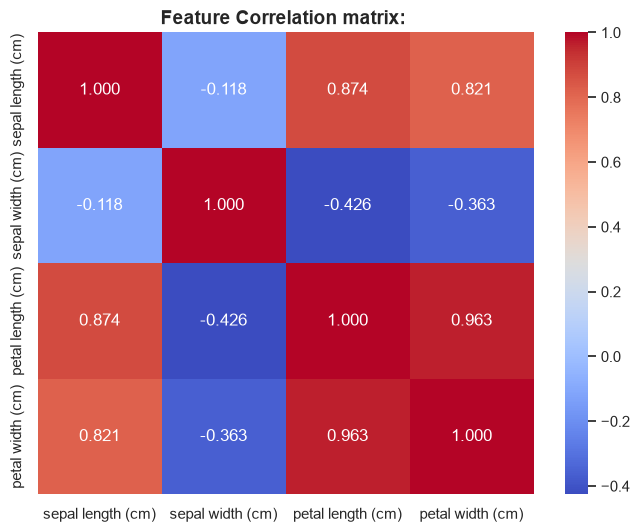

In [27]:
#Multivariate Analysis
plt.figure(figsize=(8, 6))
corr_mat=df[feature_cols].corr()    #Correlation matrix
sns.heatmap(corr_mat, annot=True, cmap='coolwarm', fmt=".3f", cbar=True)
plt.title("Feature Correlation matrix: ", fontsize=14, fontweight='bold')
plt.show()

c:\Users\msi\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\seaborn\axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
c:\Users\msi\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\seaborn\axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
c:\Users\msi\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\seaborn\axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
c:\Users\msi\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\seaborn\axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
c:\Users\msi\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\seaborn\axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  

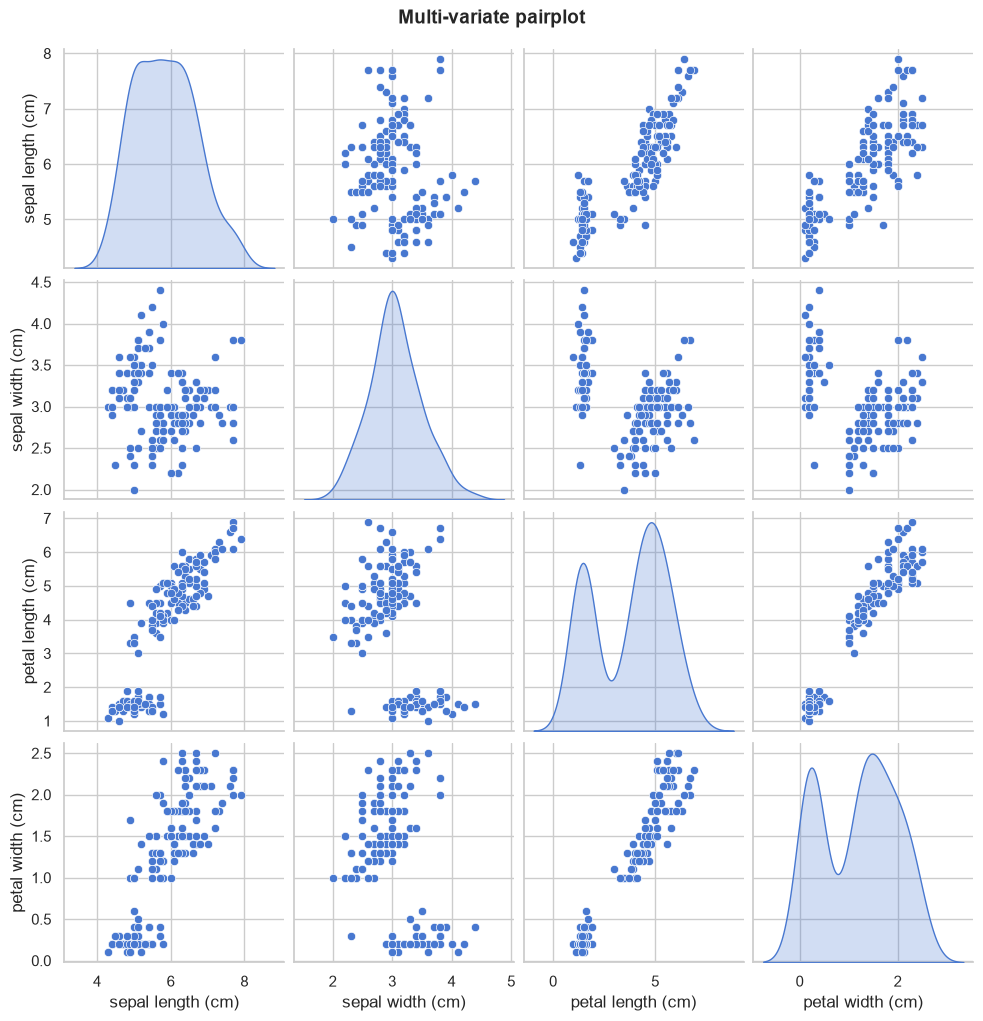

In [31]:
pairplot=sns.pairplot(df, vars=feature_cols, diag_kind='kde', palette='Set2')
pairplot.fig.suptitle("Multi-variate pairplot", y=1.02, fontsize=14, fontweight='bold')
plt.show()

In [36]:
#Class_Imbalance
class_counts=df['target'].value_counts()
class_props=df['target'].value_counts(normalize=True)*100
imbalance_summary=pd.DataFrame({'count':class_counts, 'Percentage':class_props})

print(imbalance_summary)

        count  Percentage
target                   
0          50   33.557047
1          50   33.557047
2          49   32.885906


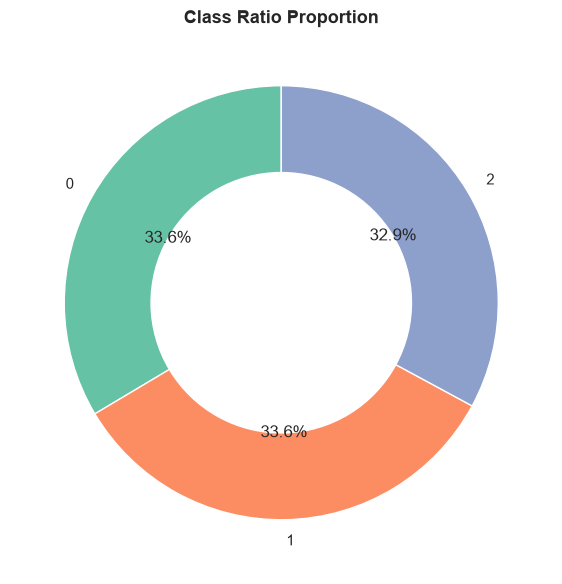

In [37]:
#Donut Chart
plt.figure(figsize=(6, 6))
counts = df['target'].value_counts()

plt.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90, 
        colors=sns.color_palette('Set2'), wedgeprops=dict(width=0.4, edgecolor='w'))

plt.title("Class Ratio Proportion", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()